In [2]:
import numpy as np
import cv2 as cv
from matplotlib import pyplot as plt
from skimage.feature import peak_local_max


# 1. Реализуйте высокочастотную фильтрацию на основе ядра Гаусса

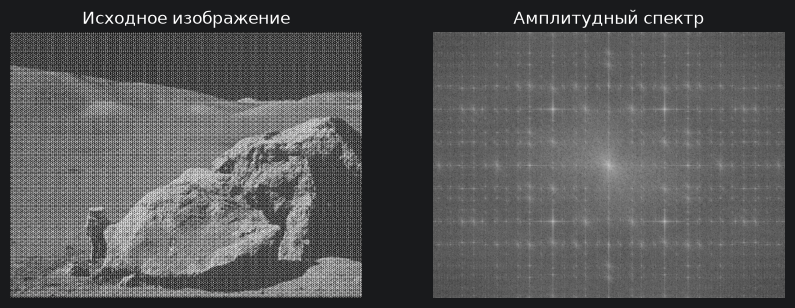

In [3]:
img = cv.imread('periodic_noise.jpg', cv.IMREAD_GRAYSCALE)

dft = cv.dft(np.float32(img), flags=cv.DFT_COMPLEX_OUTPUT)
dft_shift = np.fft.fftshift(dft)
magnitude_spectrum = 20 * np.log(cv.magnitude(dft_shift[:, :, 0],
dft_shift[:, :, 1]))

plt.figure(figsize=(10, 6))

plt.subplot(1, 2, 1)
plt.imshow(img, cmap='gray')
plt.title('Исходное изображение')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(magnitude_spectrum, cmap='gray')
plt.title('Амплитудный спектр')
plt.axis('off')

plt.show()

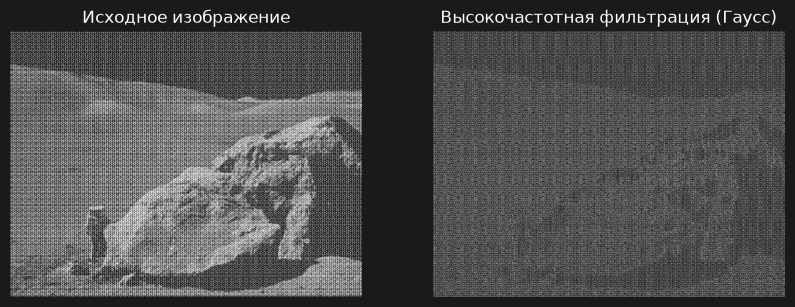

In [4]:
rows, cols = img.shape
crow, ccol = rows // 2, cols // 2
sigma = 30

x = np.arange(0, cols, 1)
y = np.arange(0, rows, 1)
X, Y = np.meshgrid(x, y)
gaussian_mask = np.exp(-((X - ccol)**2 + (Y - crow)**2) / (2 * sigma**2))

high_pass_mask = 1 - gaussian_mask

dft_shift_high_pass = dft_shift * high_pass_mask[:, :, np.newaxis]
f_ishift_high_pass = np.fft.ifftshift(dft_shift_high_pass)
img_back_high_pass = cv.idft(f_ishift_high_pass)
img_back_high_pass = cv.magnitude(img_back_high_pass[:, :, 0],
img_back_high_pass[:, :, 1])

plt.figure(figsize=(10, 6))

plt.subplot(1, 2, 1)
plt.imshow(img, cmap='gray')
plt.title('Исходное изображение')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(img_back_high_pass, cmap='gray')
plt.title('Высокочастотная фильтрация (Гаусс)')
plt.axis('off')

plt.show()

# 2. Реализуйте удаление периодического шума с помощью преобразования Фурье

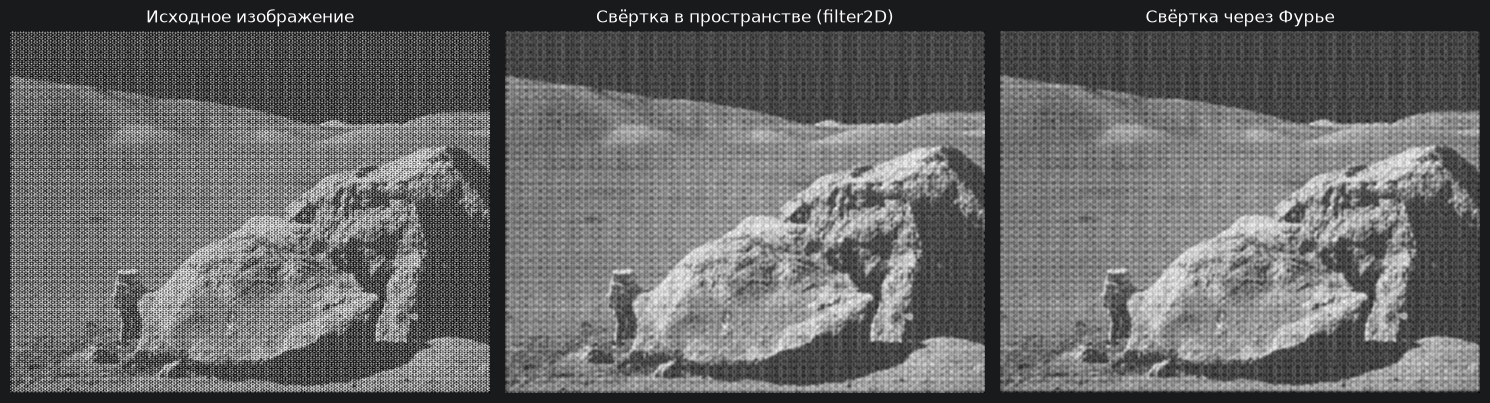

Максимальная абсолютная разница между свертками: 100


In [5]:

kernel_size = 5
kernel = cv.getGaussianKernel(kernel_size, sigma=1.5)
kernel = kernel * kernel.T

spatial_conv = cv.filter2D(img, -1, kernel)

rows, cols = img.shape

kernel_padded = np.zeros((rows, cols), dtype=np.float32) # нулями дополнили для того чтобы совпал с filter2D
k_h, k_w = kernel.shape
kernel_padded[:k_h, :k_w] = kernel

kernel_padded = np.roll(kernel_padded, -k_h // 2, axis=0)
kernel_padded = np.roll(kernel_padded, -k_w // 2, axis=1)

dft_img = cv.dft(np.float32(img), flags=cv.DFT_COMPLEX_OUTPUT)
dft_kernel = cv.dft(kernel_padded, flags=cv.DFT_COMPLEX_OUTPUT)

re = dft_img[:, :, 0] * dft_kernel[:, :, 0] - dft_img[:, :, 1] * dft_kernel[:, :, 1]
im = dft_img[:, :, 0] * dft_kernel[:, :, 1] + dft_img[:, :, 1] * dft_kernel[:, :, 0]
dft_conv = np.stack([re, im], axis=-1)

fourier_conv = cv.idft(dft_conv)
fourier_conv = fourier_conv[:, :, 0]

fourier_conv = cv.normalize(fourier_conv, None, 0, 255, cv.NORM_MINMAX).astype(np.uint8)

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(img, cmap='gray')
plt.title('Исходное изображение')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(spatial_conv, cmap='gray')
plt.title('Свёртка в пространстве (filter2D)')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(fourier_conv, cmap='gray')
plt.title('Свёртка через Фурье')
plt.axis('off')

plt.tight_layout()
plt.show()

diff = cv.absdiff(spatial_conv, fourier_conv)
print(f"Максимальная абсолютная разница между свертками: {np.max(diff)}")

# 3 Реализуйте удаление периодического шума

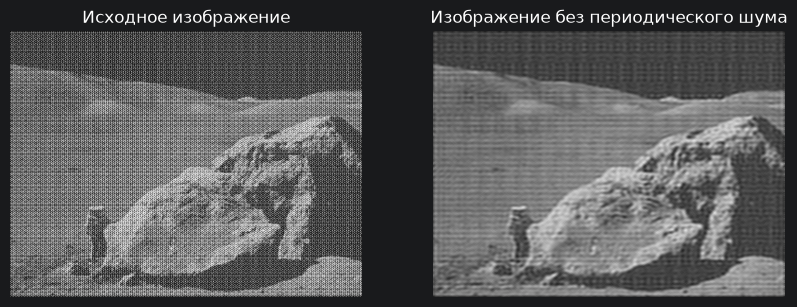

In [6]:
min_distance = 10
threshold_abs = 270
noise_coords = peak_local_max(magnitude_spectrum,
min_distance=min_distance, threshold_abs=threshold_abs)

mask_noise = np.ones_like(dft_shift)
radius = 81
for coord in noise_coords:
    cv.circle(mask_noise, (coord[1], coord[0]), radius, (0, 0), -1)

cv.circle(mask_noise, (ccol, crow), radius + 12, (0, 0), -1)
cv.circle(mask_noise, (ccol, crow), radius - 12, (1, 1), -1)

dft_shift_noise_removed = dft_shift * mask_noise
f_ishift_noise_removed = np.fft.ifftshift(dft_shift_noise_removed)
img_back_noise_removed = cv.idft(f_ishift_noise_removed)
img_back_noise_removed = cv.magnitude(img_back_noise_removed[:, :, 0], img_back_noise_removed[:, :, 1])

img_back_noise_removed = cv.normalize(img_back_noise_removed, None, 0, 255, cv.NORM_MINMAX)

plt.figure(figsize=(10, 6))

plt.subplot(1, 2, 1)
plt.imshow(img, cmap='gray')
plt.title('Исходное изображение')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(img_back_noise_removed, cmap='gray')
plt.title('Изображение без периодического шума')
plt.axis('off')

plt.show()